# From pixel to class: classifying Sentinel-2 near the Brno reservoir

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/image_classification_brno_en.ipynb)

**OpenSkyLab · notebook for the visual** [From pixel to class](https://openskylab.space/edu_viz_image_classification.html) · [česká verze](image_classification_brno_cs.ipynb)

In the visual you split pixels with an index threshold, compared classic classifiers and watched a neural network overfit. Here you do the same on a real Sentinel-2 image near the Brno reservoir with ESA WorldCover as reference and assess accuracy with a confusion matrix.

**Goal:** find an NDVI and SAVI threshold for vegetation, compare minimum distance, maximum likelihood, k-NN, random forest and a neural network on training and test pixels, and compute producer's and user's accuracy and kappa.

**Data:** Sentinel-2 L2A `S2B_33UXQ_20240814_0_L2A` (14 August 2024) from the Earth Search catalogue on AWS, a 4 × 4 km window around the Brno reservoir and Bystrc; reference ESA WorldCover 10 m 2021 v200. About 20 MB is downloaded.

**Tasks:** six. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 50 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and data

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import rasterio
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
from sklearn.neighbors import NearestCentroid, KNeighborsClassifier
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, cohen_kappa_score
warnings.filterwarnings("ignore")

STAC = "https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E015_Map.tif"
BANDS = ["coastal", "blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def read_on_grid(url, grid, resampling=Resampling.bilinear, dtype=np.float32):
    """Read a cloud raster and resample it to grid = (transform, crs, height, width)."""
    tr, crs, ny, nx = grid
    out = np.zeros((ny, nx), dtype)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + url) as src:
            reproject(rasterio.band(src, 1), out, dst_transform=tr, dst_crs=crs, resampling=resampling)
    return out

def s2_window(item_id, lon, lat, half):
    """Reflectance of all Sentinel-2 L2A bands in a square around a point (10 m grid in the tile's UTM)."""
    item = requests.get(STAC + item_id, timeout=60).json()
    epsg = item["properties"]["proj:epsg"] if "proj:epsg" in item["properties"] else int(item["properties"]["proj:code"].split(":")[1])
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    n = int(2 * half / 10)
    grid = (rasterio.transform.from_origin(x - half, y + half, 10, 10), f"EPSG:{epsg}", n, n)
    # since processing baseline 04.00 (2022) DN carry a +1000 offset; Earth Search has already removed it for newer items
    p = item["properties"]
    offset = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
    refl = {b: (read_on_grid(item["assets"][b]["href"], grid) + offset) / 10000 for b in BANDS}
    scl = read_on_grid(item["assets"]["scl"]["href"], grid, Resampling.nearest, np.uint8)
    wl = {b: item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in BANDS}
    return refl, scl, wl, grid, item

pixels per WorldCover class: {'forest': 88107, 'meadow': 14869, 'field': 19706, 'built-up': 22680, 'water': 13461}


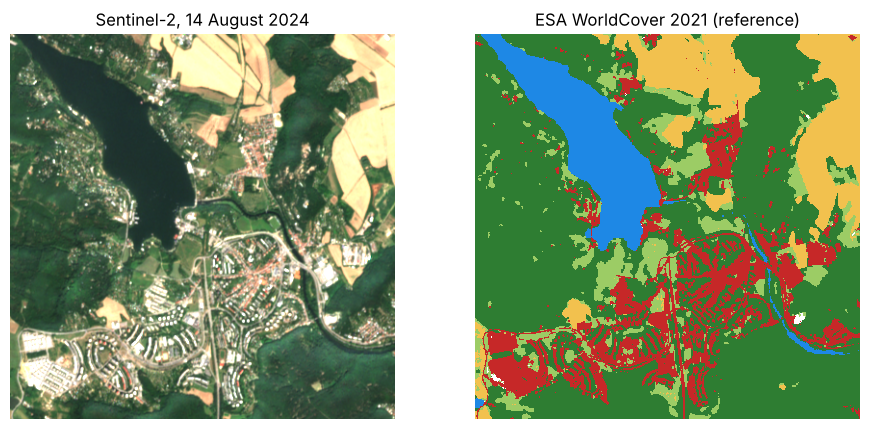

In [3]:
refl, scl, wl, grid, item = s2_window("S2B_33UXQ_20240814_0_L2A", 16.52, 49.23, 2000)
wc = read_on_grid(WORLDCOVER, grid, Resampling.nearest, np.uint8)
CLASSES = {10: "forest", 30: "meadow", 40: "field", 50: "built-up", 80: "water"}
COLORS = ["#2e7d32", "#9ccc65", "#f2c14e", "#c62828", "#1e88e5"]
FEAT = ["blue", "green", "red", "nir", "swir16", "swir22"]
X_img = np.dstack([refl[b] for b in FEAT])
ok = np.isin(scl, [4, 5, 6]) & np.isin(wc, list(CLASSES))
print("pixels per WorldCover class:", {CLASSES[k]: int(((wc == k) & ok).sum()) for k in CLASSES})
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(np.clip(np.dstack([refl["red"], refl["green"], refl["blue"]]) / 0.15, 0, 1)); ax[0].set_title("Sentinel-2, 14 August 2024")
lab = np.full(wc.shape, np.nan); [lab.__setitem__(wc == k, i) for i, k in enumerate(CLASSES)]
ax[1].imshow(lab, cmap=ListedColormap(COLORS), vmin=0, vmax=4, interpolation="nearest"); ax[1].set_title("ESA WorldCover 2021 (reference)")
for a in ax: a.axis("off")
plt.show()

## 2. NDVI threshold: two errors against each other

Vegetation = forest, meadow and field according to WorldCover, the rest = built-up and water. For each threshold we count how much vegetation we miss and how much non-vegetation we label as vegetation.

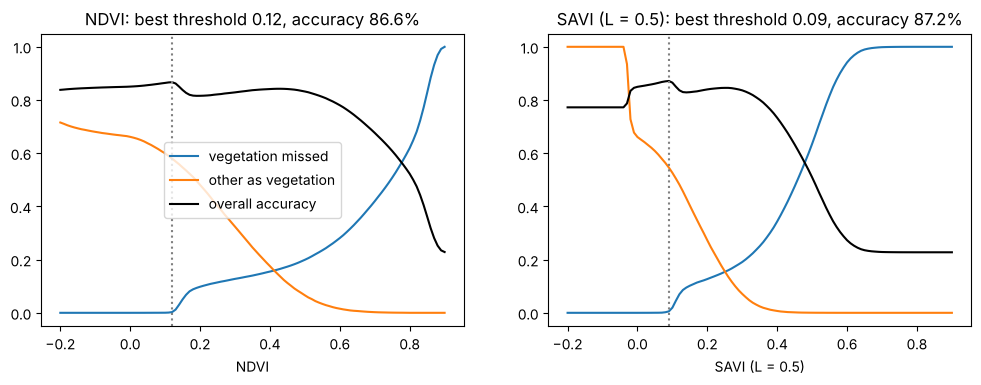

In [4]:
L = 0.5            # ◀ parameter: SAVI soil adjustment factor (0 = NDVI, 0.5 usual, 1 sparse vegetation)
nir, red = refl["nir"], refl["red"]
ndvi = (nir - red) / (nir + red)
savi = (1 + L) * (nir - red) / (nir + red + L)
veg = np.isin(wc, [10, 30, 40])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, (name, idx) in zip(ax, [("NDVI", ndvi), (f"SAVI (L = {L})", savi)]):
    thr = np.linspace(-0.2, 0.9, 111)
    miss = [np.mean(idx[ok & veg] < t_) for t_ in thr]          # vegetation missed
    false = [np.mean(idx[ok & ~veg] >= t_) for t_ in thr]       # built-up and water as vegetation
    total = [np.mean((idx[ok] >= t_) == veg[ok]) for t_ in thr]
    best = thr[int(np.argmax(total))]
    a.plot(thr, miss, label="vegetation missed"); a.plot(thr, false, label="other as vegetation"); a.plot(thr, total, "k", label="overall accuracy")
    a.axvline(best, color="gray", ls=":"); a.set(xlabel=name, title=f"{name}: best threshold {best:.2f}, accuracy {max(total):.1%}")
ax[0].legend(); plt.show()

> **✏️ Task 1.** Which NDVI threshold is best and which errors remain? Why can you not get rid of both errors at once? Which “vegetation” pixels have a low NDVI (look at the fields: after harvest there is stubble, in spring the soil may still be bare) and why are they counted as vegetation in WorldCover?

*Your answer:* 

> **✏️ Task 2.** Compare NDVI and SAVI. Set `L = 0`, `0.25` and `1`. How do the range of values and the best threshold change? Why does SAVI depend less on soil brightness and why does it hardly matter in dense vegetation?

*Your answer:* 

## 3. Training and test pixels

Neighbouring pixels are similar, so a random split would overstate accuracy. We therefore train on the northern half of the window and test on the southern half.

In [5]:
n_train = 300      # ◀ parameter: number of training pixels per class
rng = np.random.default_rng(1)
rows_ = np.arange(wc.shape[0])[:, None].repeat(wc.shape[1], 1)
def sample(mask, n):
    X, y = [], []
    for i, k in enumerate(CLASSES):
        idx = np.flatnonzero((mask & (wc == k)).ravel())
        idx = rng.choice(idx, min(n, len(idx)), replace=False)
        X.append(X_img.reshape(-1, len(FEAT))[idx]); y += [i] * len(idx)
    return np.vstack(X), np.array(y)
north, south = ok & (rows_ < wc.shape[0] // 2), ok & (rows_ >= wc.shape[0] // 2)
Xtr, ytr = sample(north, n_train)
Xte, yte = sample(south, 2000)
print("training:", np.bincount(ytr), "test:", np.bincount(yte))
names = list(CLASSES.values())

def report(model, title):
    pred = model.predict(Xte)
    cm = confusion_matrix(yte, pred, labels=range(5))
    pa, ua = np.diag(cm) / cm.sum(1), np.diag(cm) / np.maximum(cm.sum(0), 1)
    tab = pd.DataFrame(cm.astype(object), index=[f"ref {n}" for n in names], columns=names)
    tab["PA"] = pa.round(2); tab.loc["UA"] = list(ua.round(2)) + [""]
    print(f"{title}: overall accuracy test {np.mean(pred == yte):.1%}, training {model.score(Xtr, ytr):.1%}, kappa {cohen_kappa_score(yte, pred):.2f}")
    return tab

training: [300 300 300 300 300] test: [2000 2000 1865 2000 1221]


## 4. Minimum distance and maximum likelihood

In [6]:
mind = NearestCentroid().fit(Xtr, ytr)
display(report(mind, "Minimum distance"))
ml = QuadraticDiscriminantAnalysis(reg_param=1e-3).fit(Xtr, ytr)      # Gaussian maximum likelihood
display(report(ml, "Maximum likelihood"))

Minimum distance: overall accuracy test 71.5%, training 82.4%, kappa 0.64


,forest,meadow,field,built-up,water,PA
ref forest,1618,247,8,118,9,0.81
ref meadow,330,1176,205,289,0,0.59
ref field,344,493,931,96,1,0.5
ref built-up,61,113,226,1597,3,0.8
ref water,38,0,0,6,1177,0.96
UA,0.68,0.58,0.68,0.76,0.99,


Maximum likelihood: overall accuracy test 73.7%, training 83.7%, kappa 0.67


,forest,meadow,field,built-up,water,PA
ref forest,1661,211,7,116,5,0.83
ref meadow,380,1248,194,178,0,0.62
ref field,404,479,950,32,0,0.51
ref built-up,70,134,75,1721,0,0.86
ref water,25,0,0,78,1118,0.92
UA,0.65,0.6,0.77,0.81,1.0,


> **✏️ Task 3.** Read the maximum likelihood confusion matrix: rows are the reference, columns the result. Which class has a low producer's accuracy (PA, it is missed) and which a low user's accuracy (UA, other classes fall into it)? Which pairs of classes are confused most and why? Which of the two methods did better? Maximum likelihood accounts for the spread and correlation of bands within each class; why might it still not win (classes are not normally distributed, meadow and forest have similar spectra, the reference has errors)?

*Your answer:* 

## 5. How complex a model? k-NN and random forest

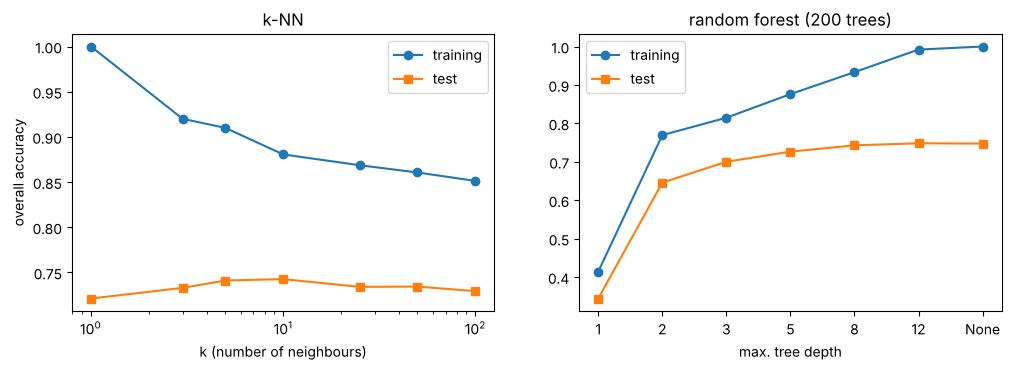

In [7]:
ks = [1, 3, 5, 10, 25, 50, 100]
depths = [1, 2, 3, 5, 8, 12, None]
acc = {"k-NN training": [], "k-NN test": [], "forest training": [], "forest test": []}
for k_ in ks:
    m = KNeighborsClassifier(k_).fit(Xtr, ytr); acc["k-NN training"].append(m.score(Xtr, ytr)); acc["k-NN test"].append(m.score(Xte, yte))
for d in depths:
    m = RandomForestClassifier(200, max_depth=d, random_state=0, n_jobs=-1).fit(Xtr, ytr)
    acc["forest training"].append(m.score(Xtr, ytr)); acc["forest test"].append(m.score(Xte, yte))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(ks, acc["k-NN training"], "o-", label="training"); ax[0].plot(ks, acc["k-NN test"], "s-", label="test")
ax[0].set(xscale="log", xlabel="k (number of neighbours)", ylabel="overall accuracy", title="k-NN"); ax[0].legend()
lbl = [str(d) for d in depths]
ax[1].plot(lbl, acc["forest training"], "o-", label="training"); ax[1].plot(lbl, acc["forest test"], "s-", label="test")
ax[1].set(xlabel="max. tree depth", title="random forest (200 trees)"); ax[1].legend(); plt.show()

> **✏️ Task 4.** With k = 1 the accuracy on training pixels is 100 % or nearly so. Why does that mean nothing? Which k and which tree depth give the best test accuracy? Describe what overfitting and underfitting look like in both plots.

*Your answer:* 

## 6. A neural network and overfitting

A small network with one hidden layer. We train it on few pixels and watch training and test accuracy over the epochs.

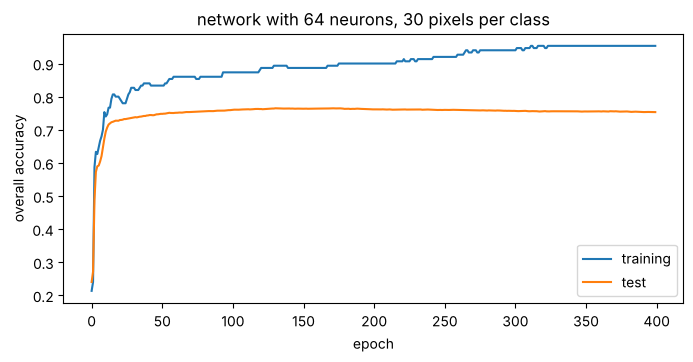

end: training 95.3%, test 75.3%; best test 76.5% at epoch 130


In [8]:
hidden = 64        # ◀ parameter: number of hidden neurons
n_small = 30       # ◀ parameter: training pixels per class (a small sample overfits more easily)
Xs, ys = sample(north, n_small)
mu, sd = Xs.mean(0), Xs.std(0)
net = MLPClassifier((hidden,), learning_rate_init=0.01, alpha=0.0, random_state=0)
hist = []
for epoch in range(400):
    net.partial_fit((Xs - mu) / sd, ys, classes=range(5))
    hist.append((net.score((Xs - mu) / sd, ys), net.score((Xte - mu) / sd, yte)))
hist = np.array(hist)
plt.figure(figsize=(8, 3.5)); plt.plot(hist[:, 0], label="training"); plt.plot(hist[:, 1], label="test")
plt.xlabel("epoch"); plt.ylabel("overall accuracy"); plt.title(f"network with {hidden} neurons, {n_small} pixels per class"); plt.legend(); plt.show()
print(f"end: training {hist[-1, 0]:.1%}, test {hist[-1, 1]:.1%}; best test {hist[:, 1].max():.1%} at epoch {hist[:, 1].argmax()}")

> **✏️ Task 5.** Try `hidden` 4, 64 and 256 and `n_small` 30 and 300. When does the network overfit (training rises, test falls or stalls)? What would help: more data, a smaller network or stopping earlier? Why is the training–test gap larger for the network than for maximum likelihood?

*Your answer:* 

## 7. Result map

Random forest, depth 12: overall accuracy test 74.8%, training 99.2%, kappa 0.68


,forest,meadow,field,built-up,water,PA
ref forest,1513,301,14,167,5,0.76
ref meadow,129,1392,192,287,0,0.7
ref field,190,681,919,75,0,0.49
ref built-up,40,61,47,1852,0,0.93
ref water,74,9,0,17,1121,0.92
UA,0.78,0.57,0.78,0.77,1.0,


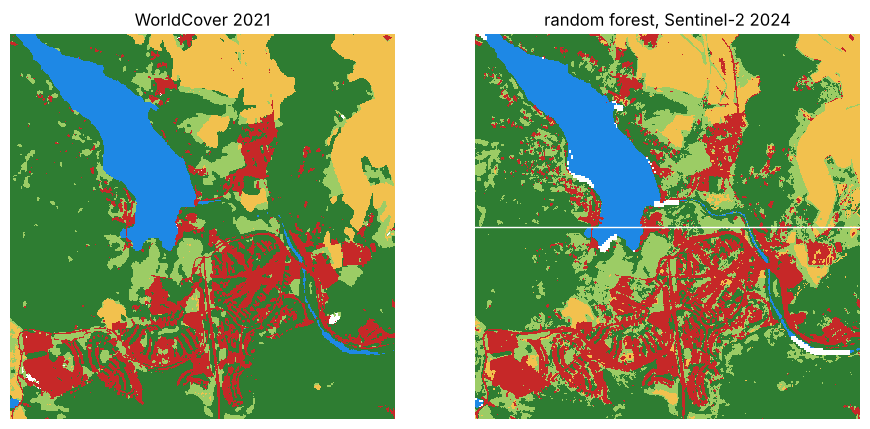

In [9]:
best = RandomForestClassifier(200, max_depth=12, random_state=0, n_jobs=-1).fit(Xtr, ytr)
display(report(best, "Random forest, depth 12"))
pred = best.predict(X_img.reshape(-1, len(FEAT))).reshape(wc.shape).astype(float)
pred[~np.isin(scl, [4, 5, 6])] = np.nan
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, (img, title) in zip(ax, [(lab, "WorldCover 2021"), (pred, "random forest, Sentinel-2 2024")]):
    a.imshow(img, cmap=ListedColormap(COLORS), vmin=0, vmax=4, interpolation="nearest"); a.set_title(title); a.axis("off")
a.axhline(wc.shape[0] / 2, color="w", lw=1); plt.show()

> **✏️ Task 6.** Find places where the map differs from WorldCover. Is the error always in the classification? Consider that WorldCover is from 2021 and has errors of its own, that a single image from one day cannot tell a meadow from a field of forage crops, nor green spring cereals from grass, and that a 10 m pixel at a forest edge is a mixture. How would you assess accuracy honestly?

*Your answer:* 

> **✏️ Extension (optional).** Compare your results with a classmate who has the notebook for another place (Roztoky, Brno, Hluboká nad Vltavou). Which classes are confused more elsewhere, and why (season of the image, type of landscape, field size)?

*Your answer:* 

---
### Data sources and references

- Copernicus Sentinel-2 data 2024, ESA (L2A, Sen2Cor); AWS Open Data registry (`sentinel-cogs`), Earth Search catalogue (Element 84). Free use with attribution.
- Zanaga, D. et al. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Huete, A. R. (1988). A soil-adjusted vegetation index (SAVI). *Remote Sensing of Environment* 25, 295–309. https://doi.org/10.1016/0034-4257(88)90106-X
- Congalton, R. G., Green, K. (2019). *Assessing the Accuracy of Remotely Sensed Data: Principles and Practices*, 3rd ed. CRC Press.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research* 12, 2825–2830.

### How to cite

OpenSkyLab (2026). From pixel to class: classifying Sentinel-2 near the Brno reservoir [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/image_classification_brno_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*